# Sales demand forecasting - EDA and results

**All data here is SYNTHETIC** (generated with a fixed seed by `src/data_gen.py`). This notebook only *reads* the
files produced by `python run_all.py`, so every number shown comes from that run. Run `run_all.py` first.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, OUT, FIG = ROOT / "data", ROOT / "outputs", ROOT / "outputs" / "figures"
raw = pd.read_csv(DATA / "raw_sales.csv", parse_dates=["week_start"])
clean = pd.read_csv(DATA / "clean_weekly_sales.csv", parse_dates=["week_start"])
res = json.load(open(OUT / "results.json"))
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3df", "figure.dpi": 100, "axes.titleweight": "bold", "axes.titlelocation": "left"})
BLUE, ORANGE, INK = "#2a78d6", "#eb6834", "#2b2a28"
print(raw.shape, clean.shape)
raw.head()

(12417, 6) (12480, 9)


,product_id,category,week_start,units_sold,price,promo_flag
0,P001,Beverages,2021-01-04,65.0,3.85,0
1,P001,Beverages,2021-01-11,50.0,3.85,0
2,P001,Beverages,2021-01-18,69.0,3.85,0
3,P001,Beverages,2021-01-25,52.0,3.85,0
4,P001,Beverages,2021-02-01,60.0,3.85,0


## 1. Data quality: what was wrong and what the cleaning did

In [2]:
dq = pd.Series(res["data_quality"], name="value").to_frame()
display(dq)
print("Negative raw values:", int((raw.units_sold < 0).sum()), "| missing/blank:", int(raw.units_sold.isna().sum()),
      "| weeks absent from raw:", int(clean.shape[0] - raw.shape[0]))

,value
rows_after_reindex,12480.000
duplicate_rows_summed,0.000
absent_rows_added,63.000
blank_values,64.000
negative_values,24.000
outliers_winsorised,59.000
imputed_weeks_flagged,151.000
zero_demand_share_pct,1.790
injected_outliers,34.000
injected_outliers_flagged,33.000


Negative raw values: 24 | missing/blank: 64 | weeks absent from raw: 63


Decisions (details in the README): negatives are returns/booking errors -> treated as missing, not as zero demand;
outliers are flagged with a *causal* robust rule (previous 13 weeks only) and winsorised; gaps are forward-filled and **flagged**
so imputed weeks are never used as scoring targets.

In [3]:
# an example of an outlier that was capped
ex = clean[clean.is_outlier == 1].merge(raw, on=["product_id", "week_start"], how="left").head(5)
ex[["product_id", "week_start", "units_sold", "units"]].rename(columns={"units_sold": "raw_units", "units": "cleaned_units"})

,product_id,week_start,raw_units,cleaned_units
0,P002,2023-06-05,265.0,124.0
1,P003,2024-12-23,391.0,382.0
2,P004,2024-09-09,78.0,57.0
3,P005,2022-01-10,101.0,92.0
4,P005,2024-02-12,85.0,81.0


## 2. Exploratory analysis

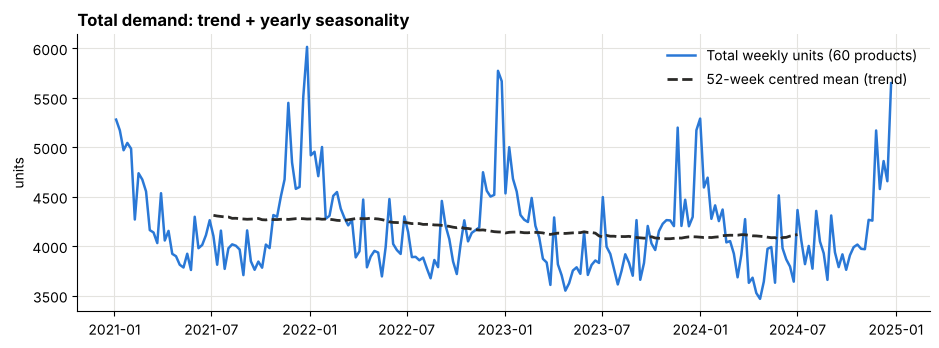

In [4]:
tot = clean.groupby("week_start")["units"].sum()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(tot.index, tot.values, color=BLUE, lw=1.8, label="Total weekly units (60 products)")
ax.plot(tot.index, tot.rolling(52, center=True).mean(), color=INK, lw=2, ls="--", label="52-week centred mean (trend)")
ax.set_title("Total demand: trend + yearly seasonality"); ax.set_ylabel("units"); ax.legend(frameon=False)
plt.show()

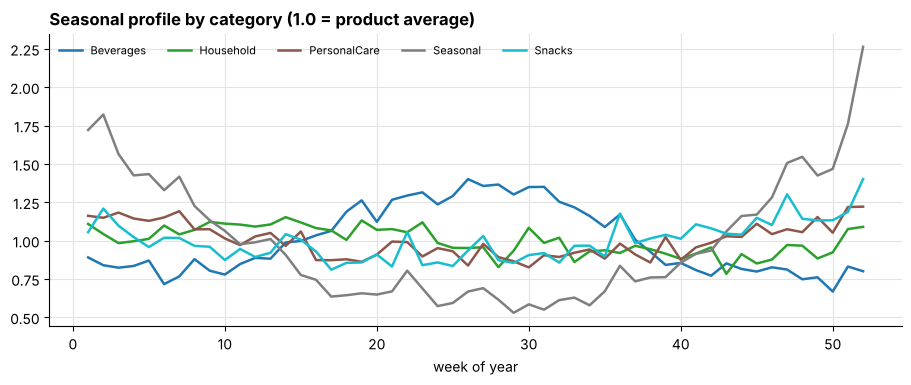

In [5]:
# yearly seasonality by category: demand relative to each product's own mean, by week of year
c = clean.copy()
c["woy"] = c.week_start.dt.isocalendar().week.astype(int)
c["rel"] = c.units / c.groupby("product_id").units.transform("mean")
seas = c[c.woy <= 52].groupby(["woy", "category"]).rel.mean().unstack()
fig, ax = plt.subplots(figsize=(11, 3.8))
seas.plot(ax=ax, lw=1.8, colormap="tab10")
ax.set_title("Seasonal profile by category (1.0 = product average)"); ax.set_xlabel("week of year"); ax.legend(frameon=False, ncol=5, fontsize=8)
plt.show()

Average relative demand, promo vs non-promo weeks:
 promo
no promo    0.947
promo       1.537
Share of promo weeks: 9.0%


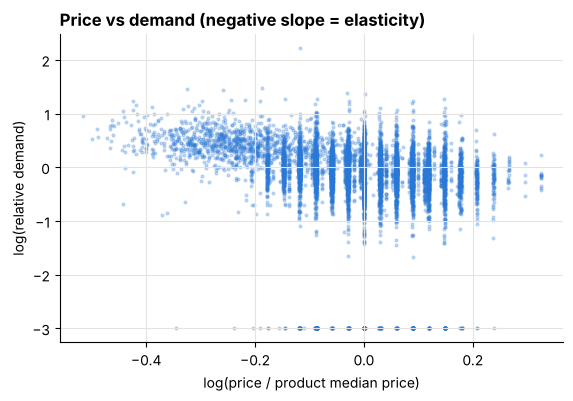

In [6]:
# promotion and price effects
c["promo"] = c.promo_flag.map({0: "no promo", 1: "promo"})
# compare promo vs non-promo weeks within the same product, de-seasonalised crudely by category-week mean
c["deseas"] = c.rel / c.groupby(["woy", "category"]).rel.transform("mean")
lift = c.groupby("promo").deseas.mean()
print("Average relative demand, promo vs non-promo weeks:\n", lift.round(3).to_string())
print("Share of promo weeks: %.1f%%" % (100 * c.promo_flag.mean()))
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.scatter(np.log(c.price / c.groupby("product_id").price.transform("median")), np.log(c.deseas.clip(lower=0.05)), s=4, alpha=0.25, color=BLUE)
ax.set_xlabel("log(price / product median price)"); ax.set_ylabel("log(relative demand)"); ax.set_title("Price vs demand (negative slope = elasticity)")
plt.show()

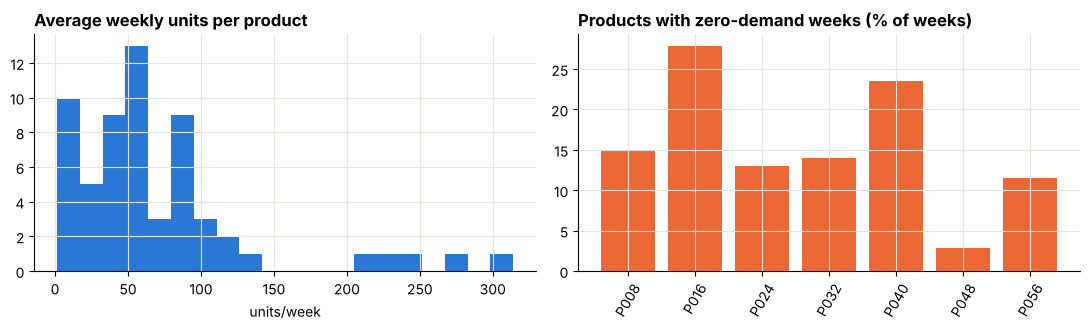

Zero-demand weeks overall: 1.79%  -> MAPE excludes them, WAPE keeps them


In [7]:
# volume distribution and zero-demand share
vol = clean.groupby("product_id").units.mean()
zero = clean.assign(z=(clean.units == 0)).groupby("product_id").z.mean() * 100
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].hist(vol, bins=20, color=BLUE); axes[0].set_title("Average weekly units per product"); axes[0].set_xlabel("units/week")
axes[1].bar(zero[zero > 0].index, zero[zero > 0].values, color=ORANGE); axes[1].set_title("Products with zero-demand weeks (% of weeks)")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()
print("Zero-demand weeks overall: %.2f%%  -> MAPE excludes them, WAPE keeps them" % (100 * (clean.units == 0).mean()))

## 3. Validation protocol and leakage checks

In [8]:
display(pd.DataFrame(res["splits"]).T)
display(pd.DataFrame(res["leakage_checks"]))
print("Hyper-parameters (walk-forward CV inside the train block only):")
for k, v in res["tuning"].items():
    print(f"  {k:13s} {v['best_params']}   CV RMSE {v['cv_rmse_mean']:.2f} +/- {v['cv_rmse_std']:.2f}")

,first_week_idx,last_week_idx,first_week,last_week
train,53,155,2022-01-10,2023-12-25
val,156,181,2024-01-01,2024-06-24
test,182,207,2024-07-01,2024-12-23


,horizon,cutoffs_tested,rows_checked,passed
0,1,5,23940,True
1,2,5,24240,True
2,3,5,24540,True


Hyper-parameters (walk-forward CV inside the train block only):
  Ridge         {'alpha': 1000}   CV RMSE 19.46 +/- 1.94
  RandomForest  {'max_depth': 12, 'min_samples_leaf': 5, 'max_features': 0.5}   CV RMSE 19.70 +/- 1.62
  XGBoost       {'max_depth': 3, 'learning_rate': 0.03, 'n_estimators': 400}   CV RMSE 19.01 +/- 1.56


The leakage test rebuilds the features after replacing **all demand after a cut-off week with garbage**: every row whose
forecast origin is on or before the cut-off must come out identical. It passes for all three horizons.

## 4. Model comparison

In [9]:
val = pd.read_csv(OUT / "validation_metrics.csv")
test = pd.read_csv(OUT / "holdout_metrics.csv")
print("Selected on validation:", res["selected_on_validation"]["baseline"], "(baseline) and", res["selected_on_validation"]["best_model"], "(best model)")
print("VALIDATION (models trained on the train block only), horizons pooled")
display(val[val.horizon == "all"].drop(columns="horizon").round(2).set_index("model"))
print("FINAL HOLDOUT (evaluated once), horizons pooled")
display(test[test.horizon == "all"].drop(columns="horizon").round(2).set_index("model"))
print("FINAL HOLDOUT, RMSE by horizon")
display(test[test.horizon != "all"].pivot(index="model", columns="horizon", values="RMSE").round(2))

Selected on validation: MovingAvg4 (baseline) and XGBoost (best model)
VALIDATION (models trained on the train block only), horizons pooled


,RMSE,MAPE_%,WAPE_%,Bias_units,n_rows,n_zero_actual_excluded_from_MAPE
model,,,,,,
SeasonalNaive,32.37,37.28,26.70,0.13,4623,69
MovingAvg4,27.54,30.62,23.21,1.52,4623,69
Ridge,18.22,23.30,16.59,-1.02,4623,69
RandomForest,18.07,23.18,16.04,-0.35,4623,69
XGBoost,17.58,22.85,15.76,-0.47,4623,69


FINAL HOLDOUT (evaluated once), horizons pooled


,RMSE,MAPE_%,WAPE_%,Bias_units,n_rows,n_zero_actual_excluded_from_MAPE
model,,,,,,
SeasonalNaive,43.44,38.92,30.48,-1.20,4614,96
MovingAvg4,34.43,28.14,23.83,-2.60,4614,96
Ridge,22.96,24.05,17.83,-0.32,4614,96
RandomForest,22.18,23.10,17.11,-0.79,4614,96
XGBoost,21.74,23.06,16.81,-0.93,4614,96


FINAL HOLDOUT, RMSE by horizon


horizon,1,2,3
model,,,
MovingAvg4,31.60,34.19,37.26
RandomForest,21.87,22.12,22.54
Ridge,22.17,22.97,23.73
SeasonalNaive,43.44,43.44,43.44
XGBoost,21.49,21.65,22.06


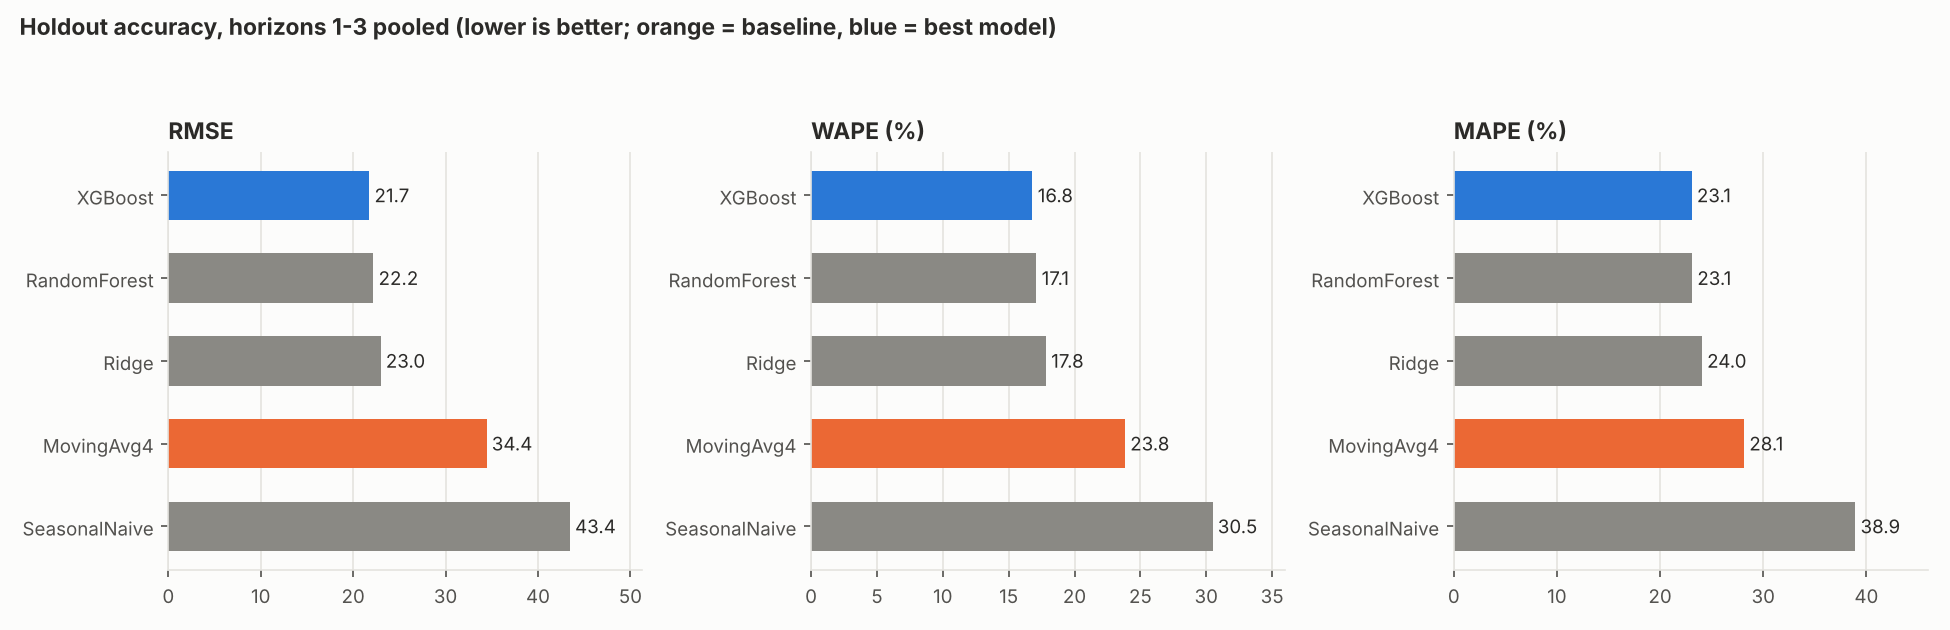

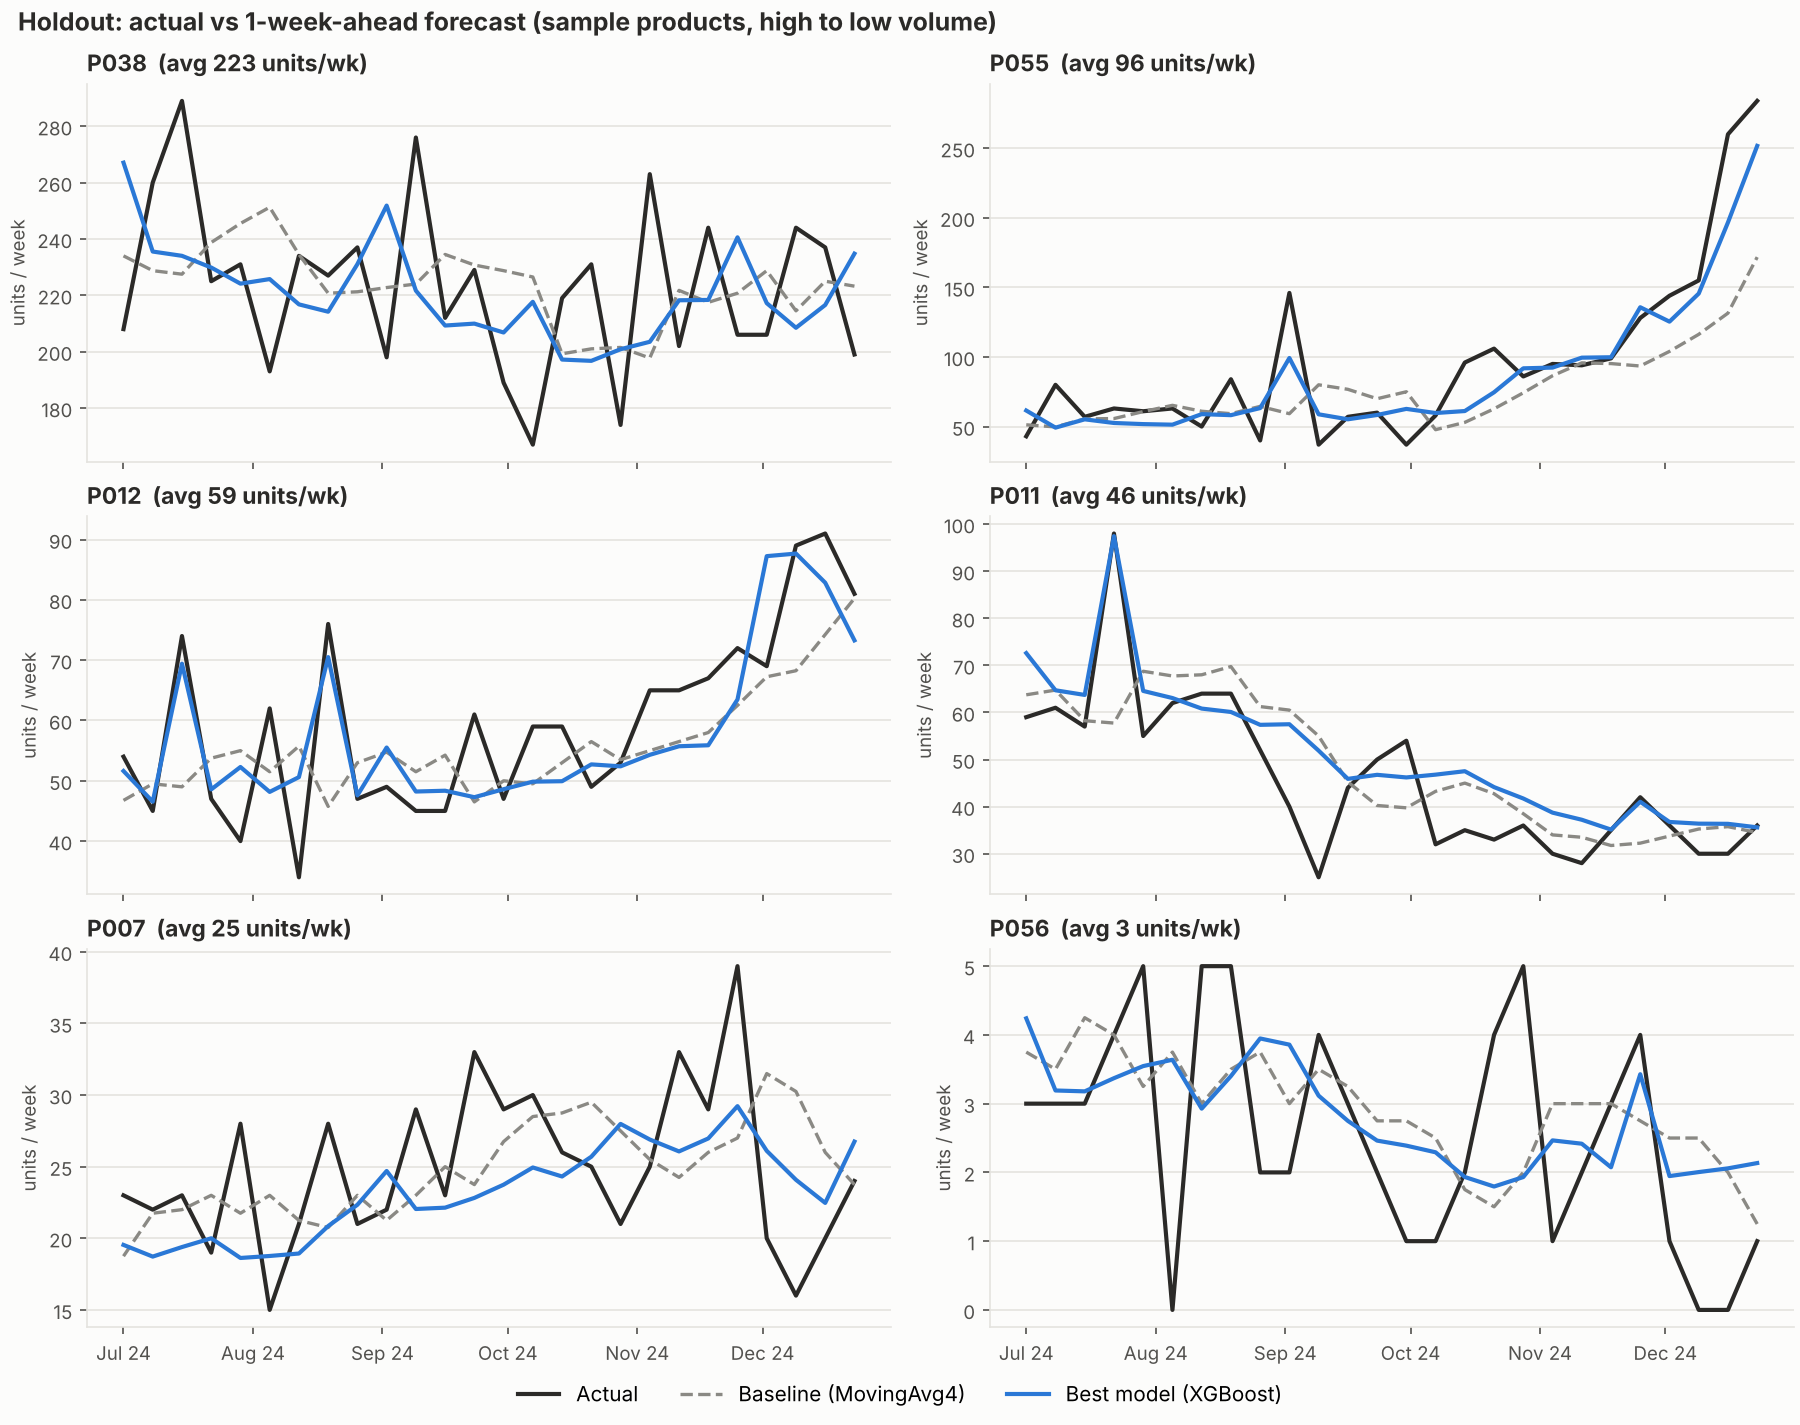

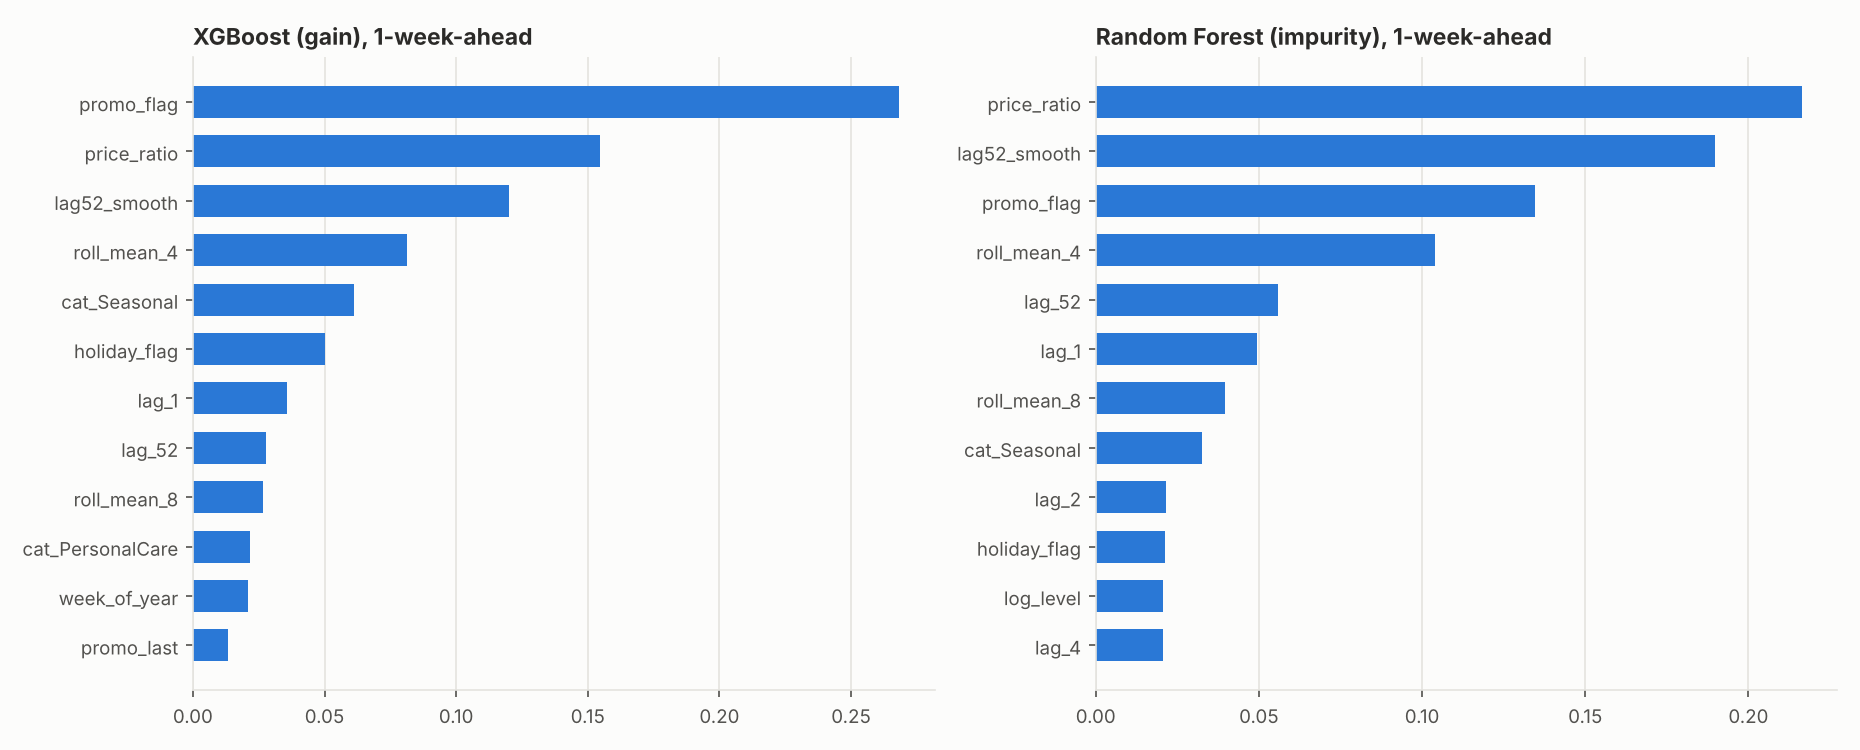

In [10]:
display(Image(FIG / "model_comparison.png"))
display(Image(FIG / "actual_vs_predicted.png"))
display(Image(FIG / "feature_importance.png"))

## 5. Reorder policy and stock-out simulation

In [11]:
inv = res["inventory"]
print("Assumptions:", inv["assumptions"])
for key, title in [("A_same_buffers", "Scenario A - same safety-stock buffers"), ("B_own_error_buffers", "Scenario B - buffers from each forecaster's own error")]:
    sc = inv[key]
    print("\n" + title)
    df = pd.DataFrame({"baseline": sc["baseline"], "best_model": sc["best_model"]}).round(2)
    display(df)
    ci = sc.get("stockout_events_reduction_ci95")
    print("stock-out events reduction %.1f%% (95%% CI %.1f to %.1f) | inventory change %.1f%% | units lost reduction %.1f%%" %
          (sc["stockout_events_reduction_%"], ci[0], ci[1], sc["inventory_change_%"], sc["units_lost_reduction_%"]))

Assumptions: {'lead_time_weeks': 2, 'review_period_weeks': 1, 'service_level': 0.95, 'holding_rate_annual': 0.2, 'lost_margin': 0.3}

Scenario A - same safety-stock buffers


,baseline,best_model
stockout_freq_%,5.90,2.08
stockout_events,85.00,30.00
fill_rate_%,96.85,99.34
units_lost,3172.00,663.00
avg_inventory_units,75.13,74.05
holding_cost,3528.58,3525.00
lost_margin_cost,9533.08,2149.75
total_cost_proxy,13061.66,5674.75


stock-out events reduction 64.7% (95% CI 47.2 to 78.9) | inventory change -1.4% | units lost reduction 79.1%

Scenario B - buffers from each forecaster's own error


,baseline,best_model
stockout_freq_%,5.90,5.90
stockout_events,85.00,85.00
fill_rate_%,96.85,98.17
units_lost,3172.00,1839.00
avg_inventory_units,75.13,45.66
holding_cost,3528.58,2255.02
lost_margin_cost,9533.08,5359.51
total_cost_proxy,13061.66,7614.53


stock-out events reduction 0.0% (95% CI -32.7 to 23.1) | inventory change -39.2% | units lost reduction 42.0%


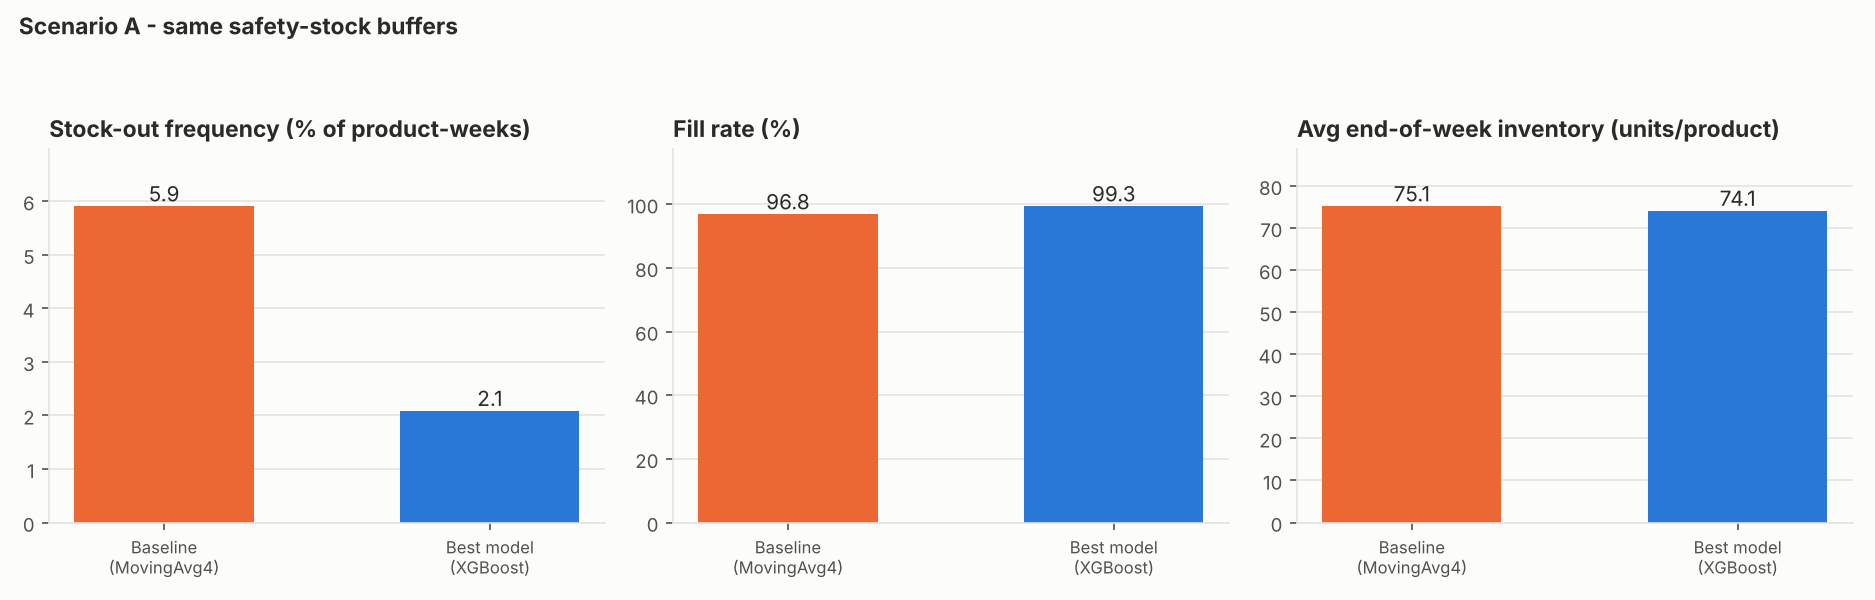

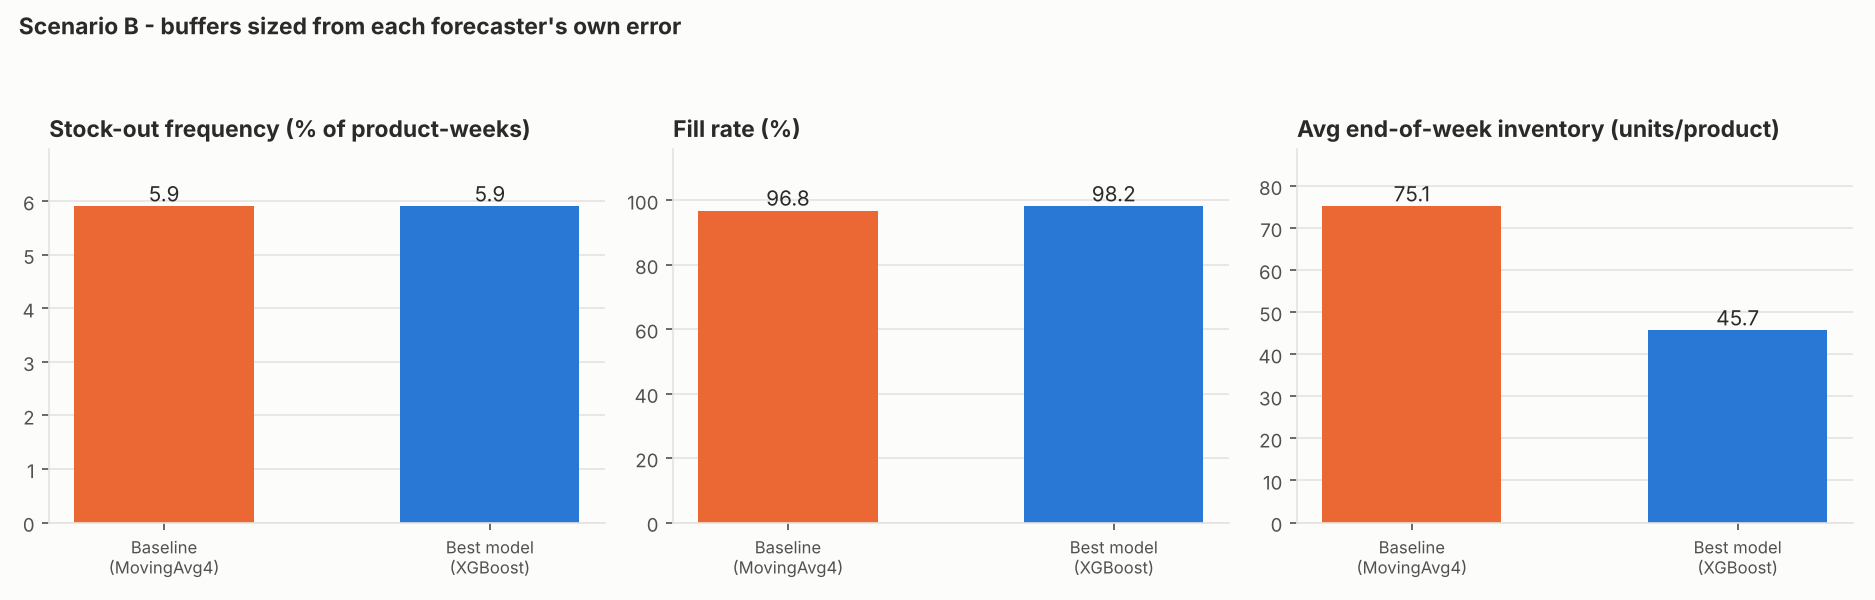

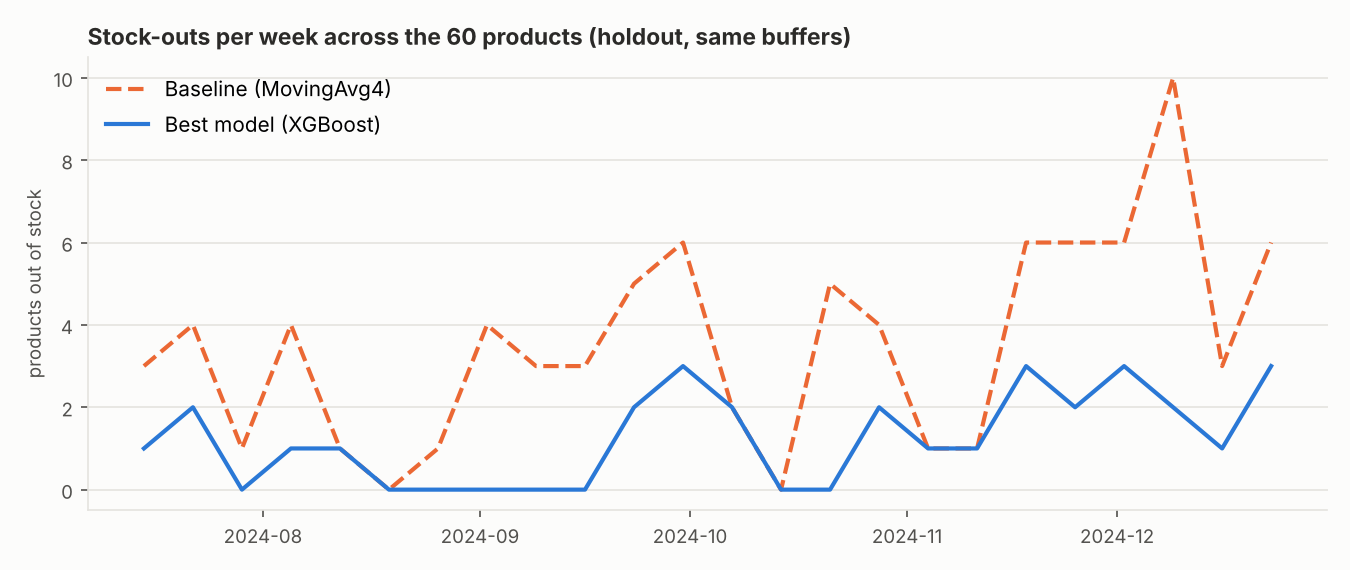

,service_level,A_base_events,A_model_events,A_reduction_%,A_inventory_change_%,B_base_events,B_model_events,B_reduction_%,B_inventory_change_%
0,0.90,130,65,50.00,-4.01,130,120,7.69,-38.65
1,0.95,85,30,64.71,-1.43,85,85,0.00,-39.22
2,0.98,58,17,70.69,0.25,58,56,3.45,-39.73


In [12]:
display(Image(FIG / "stockout_comparison.png"))
display(Image(FIG / "stockout_comparison_own_buffers.png"))
display(Image(FIG / "stockouts_by_week.png"))
display(pd.DataFrame(inv["service_level_sensitivity"]).round(2))

## 6. Takeaways

* Accuracy: see the holdout table - the learned models beat both baselines by a wide margin on this synthetic data, mostly because they use
  promo, price and holiday information that the baselines ignore. On real data the gap will usually be smaller.
* Inventory: with the **same buffers**, better forecasts cut stock-outs at roughly unchanged inventory (Scenario A).
  When the buffers are **re-sized to each forecaster's own error** (Scenario B), both policies target the same service level, so stock-out *frequency*
  stays about equal and the benefit shows up as lower inventory and fewer lost units instead.
* Limitations are listed in the README (synthetic data, no demand censoring, planned promo/price assumed known, single warehouse, etc.).